# Exploratory Data Analysis & Statistical Insights

## Retail Sales Dataset

This notebook performs exploratory data analysis on a retail sales
dataset using descriptive statistics, correlation analysis,
distribution visualizations, outlier detection, and statistical
hypothesis testing.

### Objectives

- Analyze descriptive statistics of numerical variables.
- Study relationships using correlation analysis.
- Identify distributions and potential outliers.
- Test three business hypotheses statistically.
- Summarize the five most important business findings.

In [ ]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = pd.read_csv("../data/retail-orders-clean.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Rows and Columns:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Rows and Columns:
(11, 11)

Column Names:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status', 'gross_sales', 'sales_after_discount']


In [ ]:
df.head()

,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,gross_sales,sales_after_discount
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2.0,799,10.0,Paid,1598.0,1438.20
1,RT-1002,NaN,Fresher,Bengaluru,Course Access,1.0,1499,0.0,Paid,1499.0,1499.00
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1.0,1499,0.0,Pending,1499.0,1499.00
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid,2397.0,2277.15
4,RT-1005,2026-01-09,Fresher,NaN,Mentor Session,1.0,999,0.0,Failed,999.0,999.00


In [ ]:
print("Dataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape:
(11, 11)

Data Types:
order_id                    str
order_date                  str
customer_segment            str
city                        str
category                    str
quantity                float64
unit_price                int64
discount_pct            float64
payment_status              str
gross_sales             float64
sales_after_discount    float64
dtype: object

Missing Values:
order_id                0
order_date              3
customer_segment        0
city                    1
category                0
quantity                2
unit_price              0
discount_pct            0
payment_status          0
gross_sales             2
sales_after_discount    2
dtype: int64


In [ ]:
df.describe()

,quantity,unit_price,discount_pct,gross_sales,sales_after_discount
count,9.000000,11.000000,11.000000,9.000000,9.000000
mean,1.555556,1108.090909,3.636364,1642.888889,1561.850000
std,0.726483,320.794468,5.518564,717.275304,603.499632
min,1.000000,799.000000,0.000000,799.000000,799.000000
25%,1.000000,799.000000,0.000000,999.000000,999.000000
50%,1.000000,999.000000,0.000000,1499.000000,1499.000000
75%,2.000000,1499.000000,7.500000,1998.000000,1998.000000
max,3.000000,1499.000000,15.000000,2998.000000,2548.300000


In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

summary = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Standard Deviation": df[numeric_cols].std(),
    "Minimum": df[numeric_cols].min(),
    "Q1 (25%)": df[numeric_cols].quantile(0.25),
    "Q2 (50%)": df[numeric_cols].quantile(0.50),
    "Q3 (75%)": df[numeric_cols].quantile(0.75),
    "Maximum": df[numeric_cols].max()
})

summary

,Mean,Median,Standard Deviation,Minimum,Q1 (25%),Q2 (50%),Q3 (75%),Maximum
quantity,1.555556,1.0,0.726483,1.0,1.0,1.0,2.0,3.0
unit_price,1108.090909,999.0,320.794468,799.0,799.0,999.0,1499.0,1499.0
discount_pct,3.636364,0.0,5.518564,0.0,0.0,0.0,7.5,15.0
gross_sales,1642.888889,1499.0,717.275304,799.0,999.0,1499.0,1998.0,2998.0
sales_after_discount,1561.850000,1499.0,603.499632,799.0,999.0,1499.0,1998.0,2548.3


## Descriptive Statistics

Descriptive statistics were calculated for all numerical variables
in the retail dataset. Mean and median were used to understand the
central tendency, while standard deviation was used to measure the
spread of the data. The first quartile (Q1), median (Q2), and third
quartile (Q3) were used to understand the distribution of the values.
Minimum and maximum values were also examined to identify unusual
observations and potential outliers.

In [ ]:
correlation_matrix = df[numeric_cols].corr()

correlation_matrix

,quantity,unit_price,discount_pct,gross_sales,sales_after_discount
quantity,1.000000,-0.330623,0.564288,0.761280,0.778213
unit_price,-0.330623,1.000000,-0.105271,0.312878,0.308194
discount_pct,0.564288,-0.105271,1.000000,0.737224,0.634946
gross_sales,0.761280,0.312878,0.737224,1.000000,0.988527
sales_after_discount,0.778213,0.308194,0.634946,0.988527,1.000000


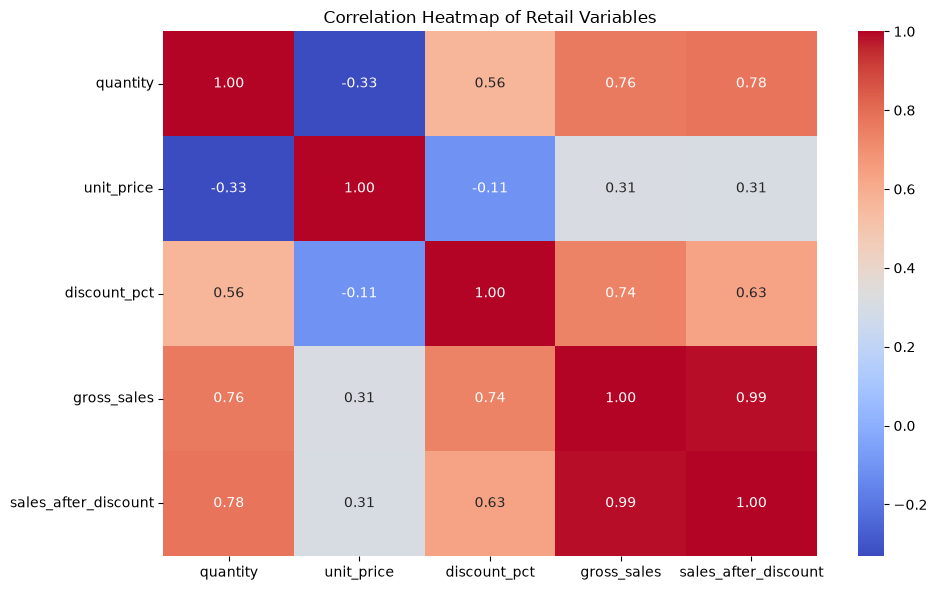

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Retail Variables")
plt.tight_layout()
plt.show()

## Correlation Analysis

The correlation matrix was used to examine the strength and direction
of relationships between the numerical variables in the retail dataset.
The heatmap provides a visual representation of these relationships,
where values closer to +1 indicate a strong positive relationship,
values closer to -1 indicate a strong negative relationship, and
values near 0 indicate a weak linear relationship.

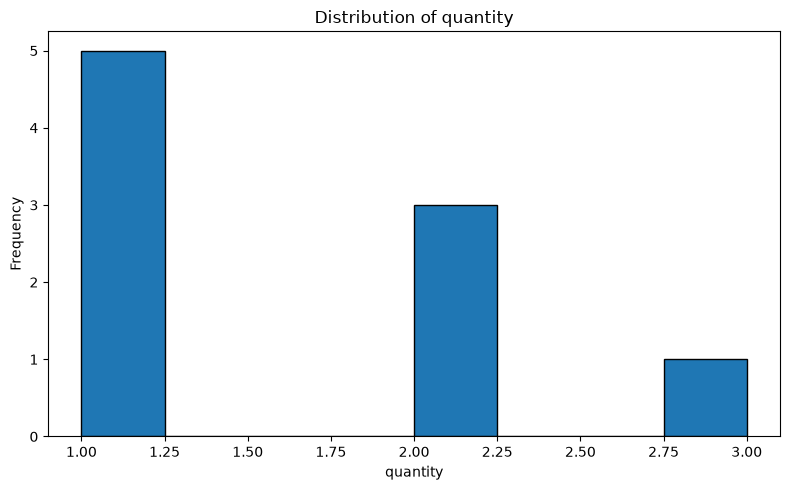

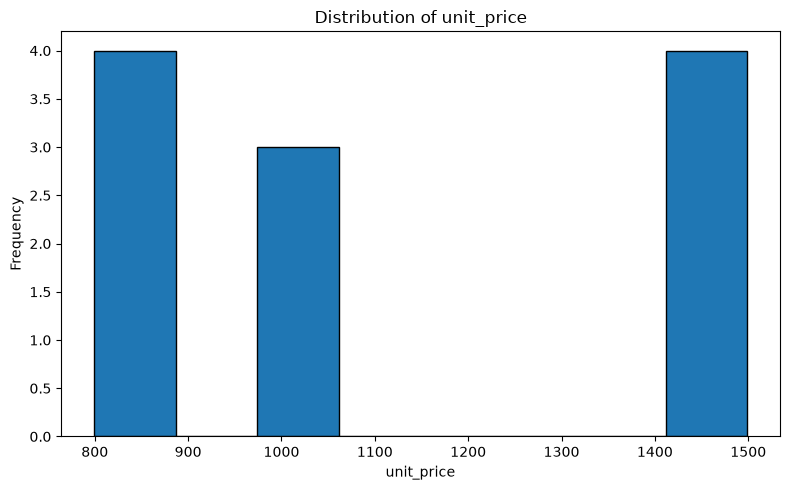

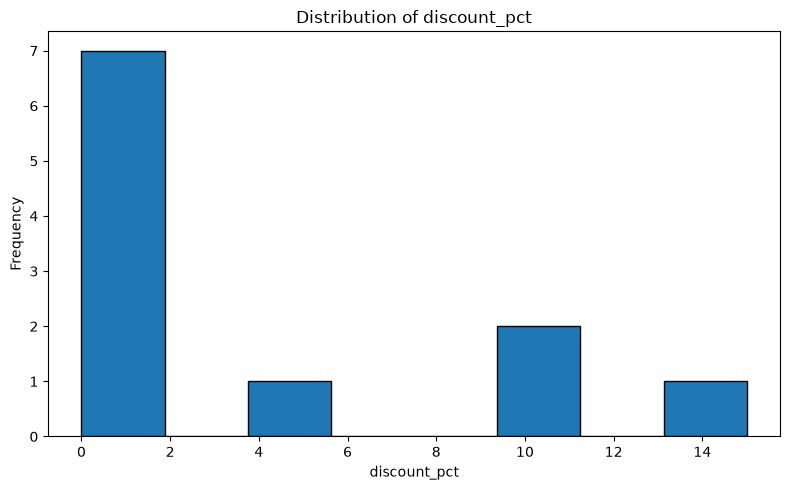

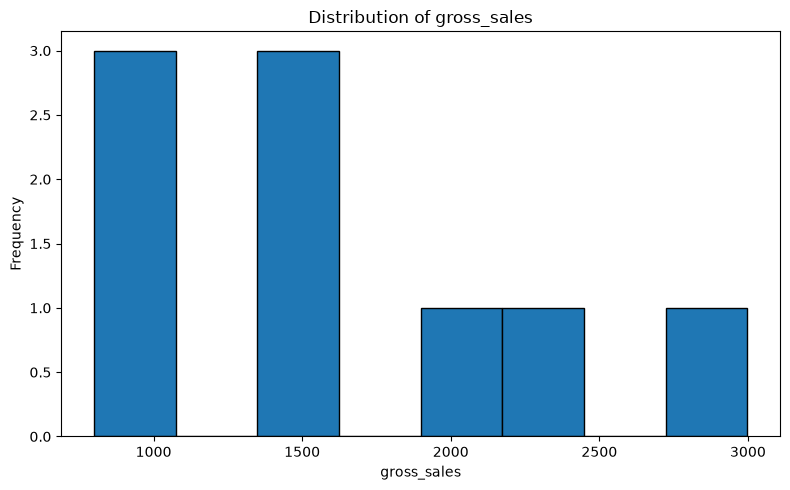

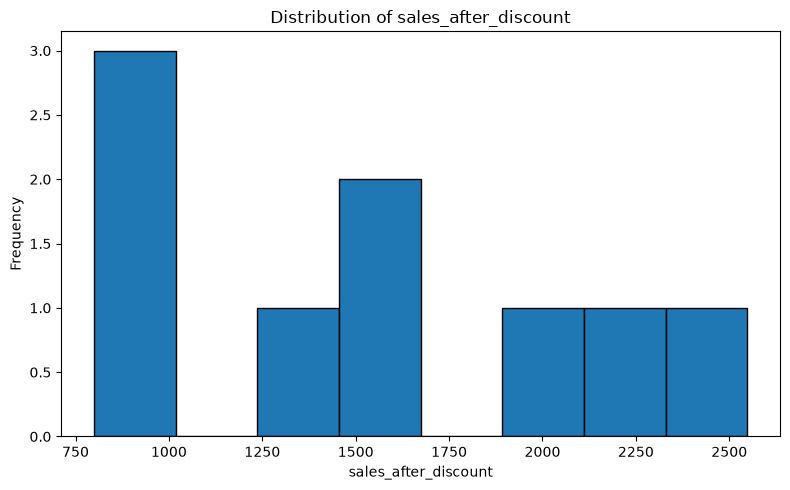

In [ ]:
for column in numeric_cols:
    plt.figure(figsize=(8, 5))
    
    plt.hist(df[column].dropna(), bins=8, edgecolor="black")
    
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    
    plt.tight_layout()
    plt.show()

## Distribution Analysis

Histograms were created for the numerical variables to understand
their distributions and frequency patterns. The charts help identify
whether the values are concentrated around certain ranges and whether
the variables show possible skewness or unusual observations.

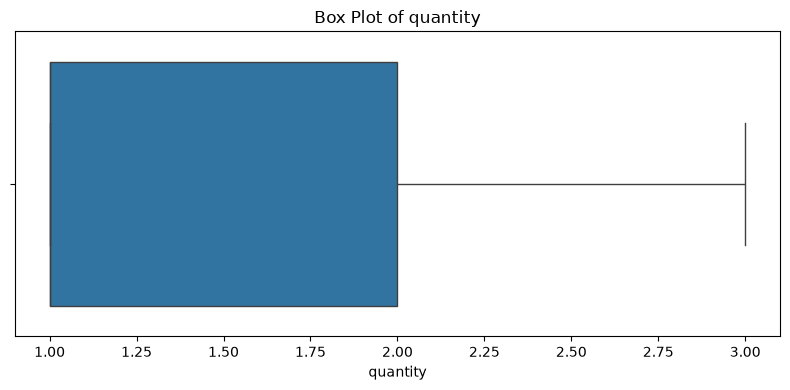

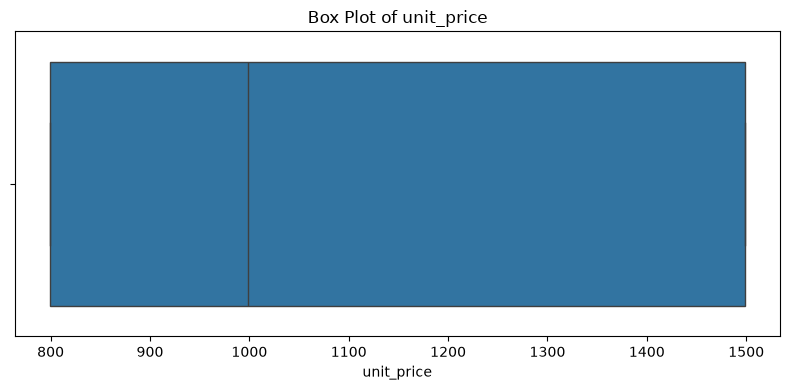

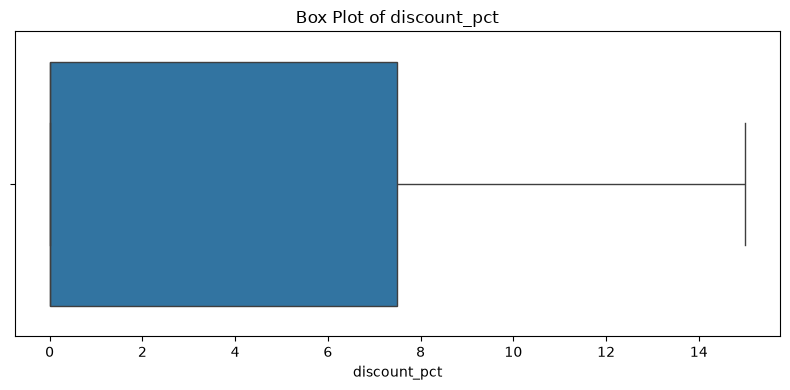

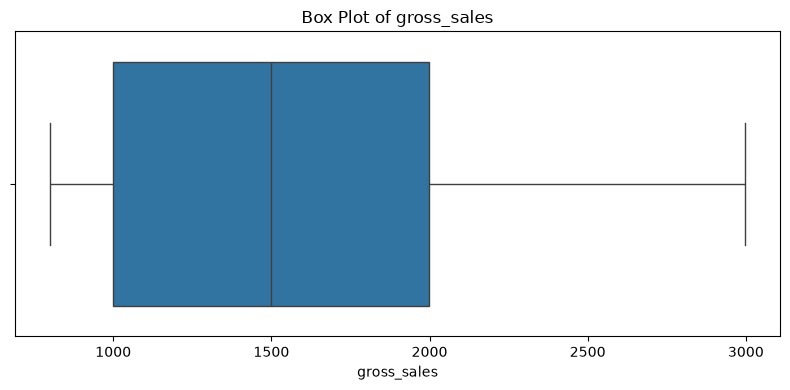

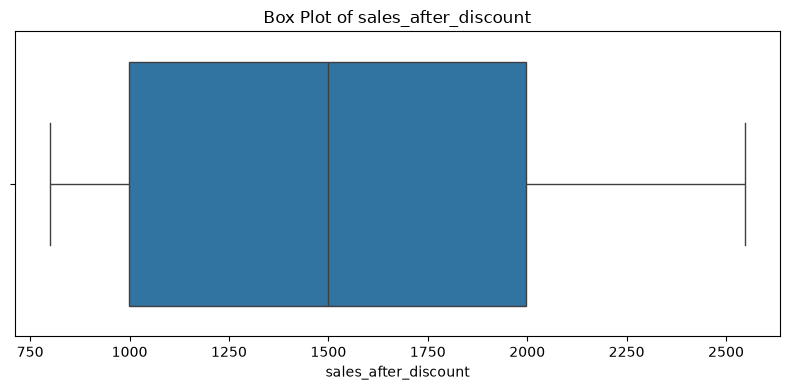

In [ ]:
for column in numeric_cols:
    plt.figure(figsize=(8, 4))
    
    sns.boxplot(x=df[column])
    
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)
    
    plt.tight_layout()
    plt.show()

## Outlier Analysis

Box plots were used to identify the spread of the numerical variables
and detect potential outliers. The box plots show the median, quartile
range, and extreme observations for each variable. Observations located
far outside the main distribution may require further investigation.

In [ ]:
for column in numeric_cols:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ][column]
    
    print(f"\n{column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", outliers.count())


quantity
Lower Bound: -0.5
Upper Bound: 3.5
Number of Outliers: 0

unit_price
Lower Bound: -251.0
Upper Bound: 2549.0
Number of Outliers: 0

discount_pct
Lower Bound: -11.25
Upper Bound: 18.75
Number of Outliers: 0

gross_sales
Lower Bound: -499.5
Upper Bound: 3496.5
Number of Outliers: 0

sales_after_discount
Lower Bound: -499.5
Upper Bound: 3496.5
Number of Outliers: 0


## Hypothesis 1: Discount Percentage and Sales After Discount

**Null Hypothesis (H₀):** There is no significant linear relationship
between discount percentage and sales after discount.

**Alternative Hypothesis (H₁):** There is a significant linear
relationship between discount percentage and sales after discount.

A Pearson correlation test will be used to test this hypothesis.

In [ ]:
temp = df[["discount_pct", "sales_after_discount"]].dropna()

correlation, p_value = stats.pearsonr(
    temp["discount_pct"],
    temp["sales_after_discount"]
)

print("Pearson Correlation:", correlation)
print("P-value:", p_value)

Pearson Correlation: 0.6349455055014317
P-value: 0.06617806306635254


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Result: Reject H₀.")
    print("There is statistically significant evidence of a linear relationship.")
else:
    print("Result: Fail to reject H₀.")
    print("There is not enough statistical evidence of a linear relationship.")

Result: Fail to reject H₀.
There is not enough statistical evidence of a linear relationship.


## Hypothesis 2: Payment Status and Sales After Discount

**Null Hypothesis (H₀):** There is no significant difference in the
average sales after discount between Paid orders and non-Paid orders.

**Alternative Hypothesis (H₁):** There is a significant difference in
the average sales after discount between Paid orders and non-Paid orders.

An independent two-sample t-test will be used to test this hypothesis.

In [ ]:
paid_orders = df[
    df["payment_status"] == "Paid"
]["sales_after_discount"].dropna()

non_paid_orders = df[
    df["payment_status"] != "Paid"
]["sales_after_discount"].dropna()

print("Paid Orders:")
print(paid_orders)

print("\nNon-Paid Orders:")
print(non_paid_orders)

Paid Orders:
0     1438.20
1     1499.00
3     2277.15
6     1998.00
8      799.00
10     999.00
Name: sales_after_discount, dtype: float64

Non-Paid Orders:
2    1499.0
4     999.0
9    2548.3
Name: sales_after_discount, dtype: float64


In [ ]:
t_stat, p_value = stats.ttest_ind(
    paid_orders,
    non_paid_orders,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -0.35260624927101
P-value: 0.7471878468643977


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Result: Reject H₀.")
    print("There is statistically significant evidence of a difference in average sales after discount.")
else:
    print("Result: Fail to reject H₀.")
    print("There is not enough statistical evidence of a difference in average sales after discount.")

Result: Fail to reject H₀.
There is not enough statistical evidence of a difference in average sales after discount.


## Hypothesis 3: Customer Segment and Sales After Discount

**Null Hypothesis (H₀):** There is no significant difference in the
average sales after discount among customer segments.

**Alternative Hypothesis (H₁):** At least one customer segment has a
different average sales after discount.

A one-way ANOVA test will be used to test this hypothesis.

In [ ]:
segment_summary = df.groupby("customer_segment")["sales_after_discount"].agg(
    ["count", "mean", "median", "std"]
)

segment_summary

,count,mean,median,std
customer_segment,,,,
Fresher,2,1249.000000,1249.00,353.553391
Professional,3,2274.483333,2277.15,275.159692
Student,4,1183.800000,1218.60,339.751125


In [ ]:
groups = [
    group["sales_after_discount"].dropna()
    for name, group in df.groupby("customer_segment")
]

f_stat, p_value = stats.f_oneway(*groups)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 11.036980879914605
P-value: 0.009762086220602338


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Result: Reject H₀.")
    print("There is statistically significant evidence that average sales differ across customer segments.")
else:
    print("Result: Fail to reject H₀.")
    print("There is not enough statistical evidence that average sales differ across customer segments.")

Result: Reject H₀.
There is statistically significant evidence that average sales differ across customer segments.


# Top 5 Critical Business Findings

1. **Sales After Discount**
   - The average sales after discount was ₹1,561.85.
   - The median was ₹1,499.00.
   - The maximum sales after discount was ₹2,548.30.
   - This indicates variation in order values across the dataset.

2. **Discount and Sales Relationship**
   - The Pearson correlation between discount percentage and sales
     after discount was 0.635.
   - However, the p-value was 0.066, which is greater than 0.05.
   - Therefore, there was not enough statistical evidence of a
     significant linear relationship in this sample.

3. **Payment Status and Sales**
   - The t-test produced a t-statistic of -0.353 and a p-value of 0.747.
   - Since the p-value was greater than 0.05, there was not enough
     statistical evidence of a difference in average sales after
     discount between Paid and non-Paid orders.

4. **Customer Segment Differences**
   - Average sales after discount differed across customer segments.
   - The ANOVA test produced an F-statistic of 11.037 and a p-value
     of 0.00976.
   - Since the p-value was below 0.05, the null hypothesis was rejected.
   - The Professional segment had the highest average sales after
     discount at ₹2,274.48.

5. **Distribution and Potential Outliers**
   - Histograms and box plots were used to examine the distribution
     and spread of the numerical variables.
   - These visualizations help identify unusual observations and
     differences in the range of order quantities, prices, discounts,
     and sales values.

# Conclusion

The exploratory data analysis examined the retail dataset using
descriptive statistics, correlation analysis, histograms, box plots,
and hypothesis testing.

The analysis showed that discount percentage did not have statistically
significant linear evidence of a relationship with sales after discount
at the 5% significance level. Similarly, there was not enough statistical
evidence of a difference in average sales between Paid and non-Paid orders.

However, the ANOVA test found statistically significant differences in
average sales after discount across customer segments. The Professional
segment had the highest average sales after discount in this dataset.

Overall, the EDA identified important patterns in retail sales while
also showing that statistical conclusions should be interpreted
carefully because the dataset contains only a small number of records.

In [ ]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (11, 11)

Columns:
['order_id', 'order_date', 'customer_segment', 'city', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_status', 'gross_sales', 'sales_after_discount']

First 5 Rows:


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,gross_sales,sales_after_discount
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2.0,799,10.0,Paid,1598.0,1438.20
1,RT-1002,NaN,Fresher,Bengaluru,Course Access,1.0,1499,0.0,Paid,1499.0,1499.00
2,RT-1003,2026-01-05,Student,Chennai,Course Access,1.0,1499,0.0,Pending,1499.0,1499.00
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3.0,799,5.0,Paid,2397.0,2277.15
4,RT-1005,2026-01-09,Fresher,NaN,Mentor Session,1.0,999,0.0,Failed,999.0,999.00


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
order_id                0
order_date              3
customer_segment        0
city                    1
category                0
quantity                2
unit_price              0
discount_pct            0
payment_status          0
gross_sales             2
sales_after_discount    2
dtype: int64

Duplicate Rows: 0


In [ ]:
# Executive KPI Calculations

total_orders = df["order_id"].nunique()

total_quantity = df["quantity"].sum()

gross_revenue = df["gross_sales"].sum()

net_revenue = df["sales_after_discount"].sum()

average_order_value = df["sales_after_discount"].mean()

average_discount = df["discount_pct"].mean()

paid_orders = (df["payment_status"].str.lower() == "paid").sum()

paid_order_rate = (paid_orders / total_orders) * 100

failed_orders = (df["payment_status"].str.lower() == "failed").sum()

pending_orders = (df["payment_status"].str.lower() == "pending").sum()


print("========== EXECUTIVE KPIs ==========")
print(f"Total Orders: {total_orders}")
print(f"Total Quantity Sold: {total_quantity:.2f}")
print(f"Gross Revenue: ₹{gross_revenue:,.2f}")
print(f"Net Revenue: ₹{net_revenue:,.2f}")
print(f"Average Order Value: ₹{average_order_value:,.2f}")
print(f"Average Discount: {average_discount:.2f}%")
print(f"Paid Orders: {paid_orders}")
print(f"Paid Order Rate: {paid_order_rate:.2f}%")
print(f"Failed Orders: {failed_orders}")
print(f"Pending Orders: {pending_orders}")

========== EXECUTIVE KPIs ==========
Total Orders: 11
Total Quantity Sold: 14.00
Gross Revenue: ₹14,786.00
Net Revenue: ₹14,056.65
Average Order Value: ₹1,561.85
Average Discount: 3.64%
Paid Orders: 7
Paid Order Rate: 63.64%
Failed Orders: 1
Pending Orders: 2


In [ ]:
# Revenue by Customer Segment

segment_revenue = (
    df.groupby("customer_segment", dropna=False)["sales_after_discount"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

segment_revenue.columns = [
    "Total Revenue",
    "Average Order Value",
    "Number of Orders"
]

print("Revenue by Customer Segment:")
display(segment_revenue)

Revenue by Customer Segment:


,Total Revenue,Average Order Value,Number of Orders
customer_segment,,,
Professional,6823.45,2274.483333,3
Student,4735.20,1183.800000,4
Fresher,2498.00,1249.000000,2


In [ ]:
category_revenue = (
    df.groupby("category", dropna=False)["sales_after_discount"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

category_revenue.columns = [
    "Total Revenue",
    "Average Order Value",
    "Number of Orders"
]

display(category_revenue)

,Total Revenue,Average Order Value,Number of Orders
category,,,
Course Access,5546.30,1848.766667,3
Learning Kit,4514.35,1504.783333,3
Mentor Session,3996.00,1332.000000,3


In [ ]:
city_revenue = (
    df.groupby("city", dropna=False)["sales_after_discount"]
      .agg(["sum", "mean", "count"])
      .sort_values("sum", ascending=False)
)

city_revenue.columns = [
    "Total Revenue",
    "Average Order Value",
    "Number of Orders"
]

display(city_revenue)

,Total Revenue,Average Order Value,Number of Orders
city,,,
Chennai,3736.20,1245.40,3
Delhi,2548.30,2548.30,1
Hyderabad,2277.15,2277.15,1
Mumbai,1998.00,1998.00,1
Bengaluru,1499.00,1499.00,1
Kochi,999.00,999.00,1
NaN,999.00,999.00,1
Pune,0.00,NaN,0


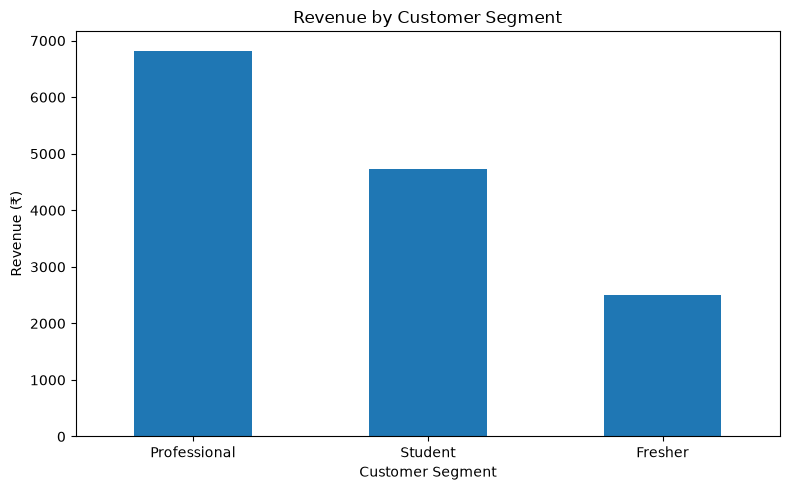

In [ ]:
import matplotlib.pyplot as plt

# Revenue by Customer Segment

segment_chart = (
    df.groupby("customer_segment")["sales_after_discount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
segment_chart.plot(kind="bar")

plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

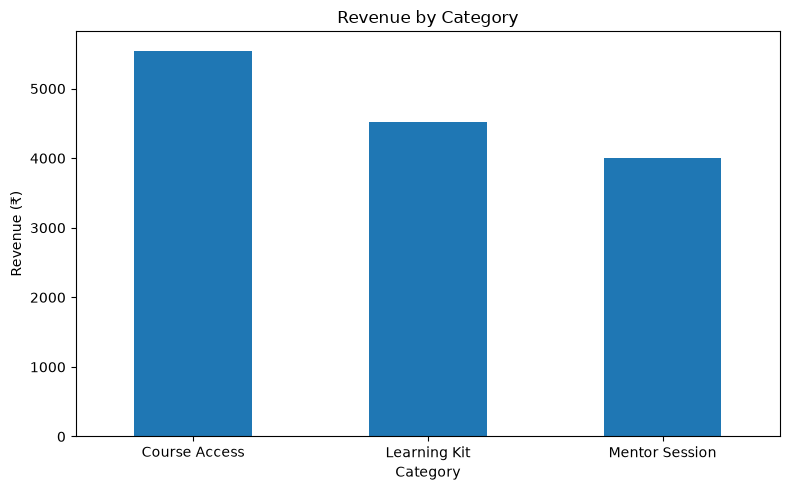

In [ ]:
# Revenue by Category

category_chart = (
    df.groupby("category")["sales_after_discount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
category_chart.plot(kind="bar")

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

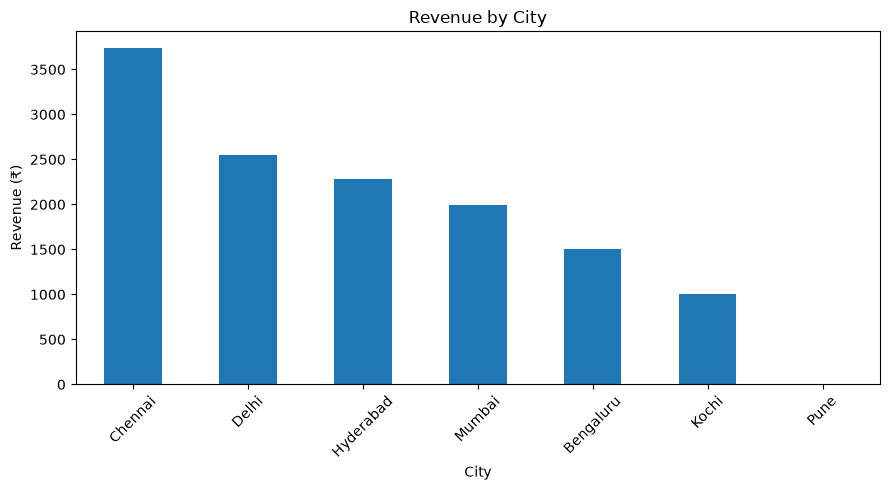

In [ ]:
# Revenue by City

city_chart = (
    df.groupby("city")["sales_after_discount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
city_chart.plot(kind="bar")

plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Risk Analysis

total_orders = df["order_id"].nunique()

# Payment risk
paid_orders = (df["payment_status"].str.lower() == "paid").sum()
pending_orders = (df["payment_status"].str.lower() == "pending").sum()
failed_orders = (df["payment_status"].str.lower() == "failed").sum()

non_paid_orders = pending_orders + failed_orders
non_paid_rate = (non_paid_orders / total_orders) * 100

# Revenue concentration
total_revenue = df["sales_after_discount"].sum()

professional_revenue = (
    df[df["customer_segment"] == "Professional"]["sales_after_discount"].sum()
)

course_revenue = (
    df[df["category"] == "Course Access"]["sales_after_discount"].sum()
)

professional_share = (professional_revenue / total_revenue) * 100
course_share = (course_revenue / total_revenue) * 100

# Data quality risks
missing_dates = df["order_date"].isna().sum()
missing_cities = df["city"].isna().sum()
missing_quantity = df["quantity"].isna().sum()
missing_revenue = df["sales_after_discount"].isna().sum()

print("RISK ANALYSIS")
print("-" * 40)

print(f"Non-paid orders: {non_paid_orders}")
print(f"Non-paid order rate: {non_paid_rate:.2f}%")

print(f"Professional revenue share: {professional_share:.2f}%")
print(f"Course Access revenue share: {course_share:.2f}%")

print(f"Missing order dates: {missing_dates}")
print(f"Missing cities: {missing_cities}")
print(f"Missing quantities: {missing_quantity}")
print(f"Missing revenue values: {missing_revenue}")

RISK ANALYSIS
----------------------------------------
Non-paid orders: 3
Non-paid order rate: 27.27%
Professional revenue share: 48.54%
Course Access revenue share: 39.46%
Missing order dates: 3
Missing cities: 1
Missing quantities: 2
Missing revenue values: 2


## Key Business Risks

1. **Payment Risk:** 3 out of 11 orders are currently pending or failed, representing 27.27% of orders. This creates a potential revenue collection risk.

2. **Revenue Concentration Risk:** Professional customers contribute approximately 48.55% of total net revenue. Strong performance from this segment is valuable, but excessive dependence on one segment can create concentration risk.

3. **Category Concentration:** Course Access contributes approximately 39.45% of net revenue, making it an important revenue driver.

4. **Data Quality Risk:** Missing order dates, quantities, city information, and revenue values can reduce the reliability of business reporting.

5. **Small Sample Risk:** The analysis contains only 11 orders. Therefore, the findings should be treated as directional insights rather than conclusions that represent the entire customer base.

## Strategic Recommendations

### Recommendation 1: Focus on the Professional Customer Segment

Professional customers generate the highest revenue and average order value. The segment contributes approximately 48.54% of total net revenue.

**Action:** Create targeted offers, premium packages, and retention campaigns for Professional customers.

**Expected benefit:** Increase revenue from high-value customers and improve customer retention.

---

### Recommendation 2: Expand Course Access

Course Access is the highest-revenue category, generating approximately 39.46% of total net revenue.

**Action:** Promote Course Access through bundles, cross-selling, and targeted campaigns. Course Access can also be combined with Learning Kits or Mentor Sessions.

**Expected benefit:** Increase sales from the strongest-performing product category.

---

### Recommendation 3: Reduce Payment and Data Risks

Three orders are currently pending or failed, representing 27.27% of total orders. The dataset also contains missing dates, quantities, city information, and revenue values.

**Action:** Introduce payment follow-up procedures and improve mandatory data-entry and validation checks.

**Expected benefit:** Improve payment recovery, reporting accuracy, and management decision-making.

In [ ]:
# ROI Projection - Scenario Analysis

# Recommendation 1: Professional Segment
professional_revenue = 6823.45
professional_uplift = professional_revenue * 0.10
professional_cost = 250
professional_net_benefit = professional_uplift - professional_cost
professional_roi = (professional_net_benefit / professional_cost) * 100

# Recommendation 2: Course Access
course_revenue = 5546.30
course_uplift = course_revenue * 0.10
course_cost = 200
course_net_benefit = course_uplift - course_cost
course_roi = (course_net_benefit / course_cost) * 100

# Recommendation 3: Payment Recovery
pending_failed_revenue = 4047.30
recovery_rate = 0.50
recovered_revenue = pending_failed_revenue * recovery_rate
payment_cost = 300
payment_net_benefit = recovered_revenue - payment_cost
payment_roi = (payment_net_benefit / payment_cost) * 100

print("ROI PROJECTION")
print("-" * 50)

print(f"Professional Segment:")
print(f"  Projected incremental revenue: ₹{professional_uplift:,.2f}")
print(f"  Estimated cost: ₹{professional_cost:,.2f}")
print(f"  Net benefit: ₹{professional_net_benefit:,.2f}")
print(f"  ROI: {professional_roi:.2f}%")

print()

print(f"Course Access:")
print(f"  Projected incremental revenue: ₹{course_uplift:,.2f}")
print(f"  Estimated cost: ₹{course_cost:,.2f}")
print(f"  Net benefit: ₹{course_net_benefit:,.2f}")
print(f"  ROI: {course_roi:.2f}%")

print()

print(f"Payment Recovery:")
print(f"  Projected recovered revenue: ₹{recovered_revenue:,.2f}")
print(f"  Estimated cost: ₹{payment_cost:,.2f}")
print(f"  Net benefit: ₹{payment_net_benefit:,.2f}")
print(f"  ROI: {payment_roi:.2f}%")

ROI PROJECTION
--------------------------------------------------
Professional Segment:
  Projected incremental revenue: ₹682.35
  Estimated cost: ₹250.00
  Net benefit: ₹432.35
  ROI: 172.94%

Course Access:
  Projected incremental revenue: ₹554.63
  Estimated cost: ₹200.00
  Net benefit: ₹354.63
  ROI: 177.31%

Payment Recovery:
  Projected recovered revenue: ₹2,023.65
  Estimated cost: ₹300.00
  Net benefit: ₹1,723.65
  ROI: 574.55%


## ROI Projection Assumptions

The ROI estimates are scenario-based projections intended for decision planning. They are not historical results or guaranteed returns.

- Professional segment: assumes a 10% revenue uplift with an estimated implementation cost of ₹250.
- Course Access: assumes a 10% revenue uplift with an estimated implementation cost of ₹200.
- Payment recovery: assumes recovery of 50% of pending/failed order value with an estimated implementation cost of ₹300.

These assumptions should be validated using larger datasets and actual campaign or operational costs before implementation.

## Implementation Timeline

### Phase 1 — First 30 Days: Prepare and Launch

- Identify and prioritize Professional customers.
- Design targeted offers for Professional customers.
- Promote Course Access through bundles and cross-selling.
- Set up payment follow-up for pending and failed orders.
- Introduce basic data validation rules.

### Phase 2 — Days 31–60: Monitor and Optimize

- Track Professional customer response and revenue.
- Measure Course Access sales after promotional activities.
- Monitor payment recovery rates.
- Review data quality improvements.
- Adjust campaigns based on early performance.

### Phase 3 — Days 61–90: Scale Successful Actions

- Expand the best-performing Professional customer campaigns.
- Scale successful Course Access bundles.
- Standardize the payment recovery process.
- Continue improving data quality controls.
- Present performance results to management for further investment decisions.